In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Second dataset check. Does our final CNN still work on different
# data? This one is 10 classes, 1024 samples per signal, captured
# on lab hardware instead of being purely synthetic.
# Same architecture and training settings as final.ipynb - no
# retuning for this dataset.

import os, random, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
import tensorflow as tf
from tensorflow.keras import layers, models

CSV_PATH   = "/content/drive/MyDrive/PDQ_10c_Clasiffy_data.csv"   
OUTPUT_DIR = "/content/drive/MyDrive/outputs_pdq10c"
os.makedirs(OUTPUT_DIR, exist_ok=True)
RANDOM_STATE, TEST_SIZE, EPOCHS = 42, 0.20, 40
FINAL_FILTERS, FINAL_KERNELS = (32, 64, 128), (3, 3, 3)
RUN_CV = True

def set_seed(s=RANDOM_STATE):
    np.random.seed(s); random.seed(s); tf.random.set_seed(s)
set_seed()
print("GPU:", tf.config.list_physical_devices("GPU"))

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
# Different format to SEED - one CSV, label in the last column.
df = pd.read_csv(CSV_PATH)                      # header row present
y = df.iloc[:, -1].astype(int).values           # label = last column
X_raw = df.iloc[:, :-1].values.astype(np.float32)
del df
classes = sorted(np.unique(y)); class_names = [str(c) for c in classes]
N_SAMPLES = X_raw.shape[1]
X_all = X_raw.reshape(-1, N_SAMPLES, 1)

# quick checks that the file loaded the way we expected

assert N_SAMPLES == 1024 and len(classes) == 10 and not np.isnan(X_raw).any()
print(X_raw.shape, "classes:", classes)
print(pd.Series(y).value_counts().sort_index().to_string())
print(f"amplitude: min {X_raw.min():.2f} max {X_raw.max():.2f} std {X_raw.std():.3f}")

(5000, 1024) classes: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]
0    500
1    500
2    500
3    500
4    500
5    500
6    500
7    500
8    500
9    500
amplitude: min -10.80 max 10.67 std 0.716


In [ ]:
# New 80/20 split for this dataset, same seed and stratify.
trainval_idx, test_idx = train_test_split(np.arange(len(y)), test_size=TEST_SIZE,
                                          random_state=RANDOM_STATE, stratify=y)
np.save(f"{OUTPUT_DIR}/trainval_idx.npy", trainval_idx); np.save(f"{OUTPUT_DIR}/test_idx.npy", test_idx)
assert len(set(trainval_idx) & set(test_idx)) == 0
print(f"{len(classes)} classes | train+val pool: {len(trainval_idx)} | unseen test: {len(test_idx)}")

10 classes | train+val pool: 4000 | unseen test: 1000


In [ ]:
# Same as the final model. Works on 1024 samples without changes
# because GAP doesn't care about the input length.
def build_model(n_classes, n_samples, filters=FINAL_FILTERS, kernel_sizes=FINAL_KERNELS):
    x_in = layers.Input(shape=(n_samples, 1)); x = x_in
    for i in range(3):
        x = layers.Conv1D(filters[i], kernel_size=kernel_sizes[i], activation="relu", padding="same")(x)
        x = layers.BatchNormalization()(x)
        if i < 2: x = layers.MaxPooling1D(pool_size=2)(x)
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(n_classes, activation="softmax")(x)
    m = models.Model(x_in, out)
    m.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

def make_callbacks():
    return [tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
            tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6)]

build_model(len(classes), N_SAMPLES).summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 1024, 1)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 1024, 32)       │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1024, 32)       │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 512, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 512, 64)        │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 512, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 256, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 256, 128)       │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 256, 128)       │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 40,842 (159.54 KB)

 Trainable params: 40,394 (157.79 KB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/40
107/107 - 22s - 207ms/step - accuracy: 0.5171 - loss: 1.5456 - val_accuracy: 0.1000 - val_loss: 2.5997 - learning_rate: 5.0000e-04
Epoch 2/40
107/107 - 1s - 10ms/step - accuracy: 0.6859 - loss: 0.9847 - val_accuracy: 0.1000 - val_loss: 5.7408 - learning_rate: 5.0000e-04
Epoch 3/40
107/107 - 1s - 8ms/step - accuracy: 0.7497 - loss: 0.7613 - val_accuracy: 0.1000 - val_loss: 9.2581 - learning_rate: 5.0000e-04
Epoch 4/40
107/107 - 1s - 8ms/step - accuracy: 0.7971 - loss: 0.6243 - val_accuracy: 0.1117 - val_loss: 7.6951 - learning_rate: 5.0000e-04
Epoch 5/40
107/107 - 1s - 8ms/step - accuracy: 0.8374 - loss: 0.5083 - val_accuracy: 0.2167 - val_loss: 5.2555 - learning_rate: 2.5000e-04
Epoch 6/40
107/107 - 1s - 8ms/step - accuracy: 0.8418 - loss: 0.4593 - val_accuracy: 0.4167 - val_loss: 3.4033 - learning_rate: 2.5000e-04
Epoch 7/40
107/107 - 1s - 8ms/step - accuracy: 0.8709 - loss: 0.4051 - val_accuracy: 0.6167 - val_loss: 1.0356 - learning_rate: 2.5000e-04
Epoch 8/40
107/107 - 1s

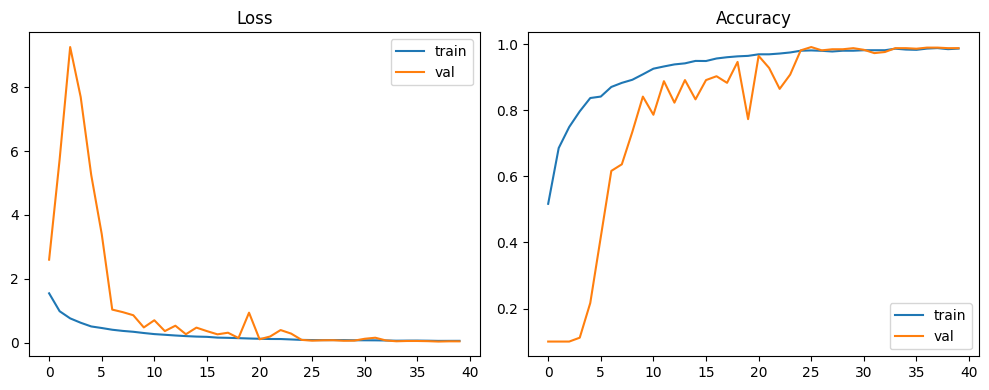

In [ ]:
# Labels are already 0-9 so no LabelEncoder needed here.
fit_idx, es_idx = train_test_split(trainval_idx, test_size=0.15, random_state=RANDOM_STATE, stratify=y[trainval_idx])
tf.keras.backend.clear_session(); set_seed()
model = build_model(len(classes), N_SAMPLES)
t0 = time.time()
history = model.fit(X_all[fit_idx], y[fit_idx], validation_data=(X_all[es_idx], y[es_idx]),
                    epochs=EPOCHS, batch_size=32, callbacks=make_callbacks(), verbose=2)
print(f"Trained in {time.time()-t0:.0f}s, {len(history.history['loss'])} epochs")
model.save(f"{OUTPUT_DIR}/pdq10c_model.keras")

plt.figure(figsize=(10,4))
plt.subplot(1,2,1); plt.plot(history.history["loss"], label="train"); plt.plot(history.history["val_loss"], label="val"); plt.title("Loss"); plt.legend()
plt.subplot(1,2,2); plt.plot(history.history["accuracy"], label="train"); plt.plot(history.history["val_accuracy"], label="val"); plt.title("Accuracy"); plt.legend()
plt.tight_layout(); plt.savefig(f"{OUTPUT_DIR}/training_curves.png", dpi=150); plt.show()

TEST ACCURACY (unseen 20%, 1000 signals): 97.70%
Macro F1: 0.9775

              precision    recall  f1-score   support

           0     0.8475    1.0000    0.9174       100
           1     1.0000    0.9500    0.9744       100
           2     1.0000    0.9700    0.9848       100
           3     1.0000    1.0000    1.0000       100
           4     1.0000    1.0000    1.0000       100
           5     0.9901    1.0000    0.9950       100
           6     1.0000    0.9200    0.9583       100
           7     1.0000    0.9700    0.9848       100
           8     0.9706    0.9900    0.9802       100
           9     0.9898    0.9700    0.9798       100

    accuracy                         0.9770      1000
   macro avg     0.9798    0.9770    0.9775      1000
weighted avg     0.9798    0.9770    0.9775      1000



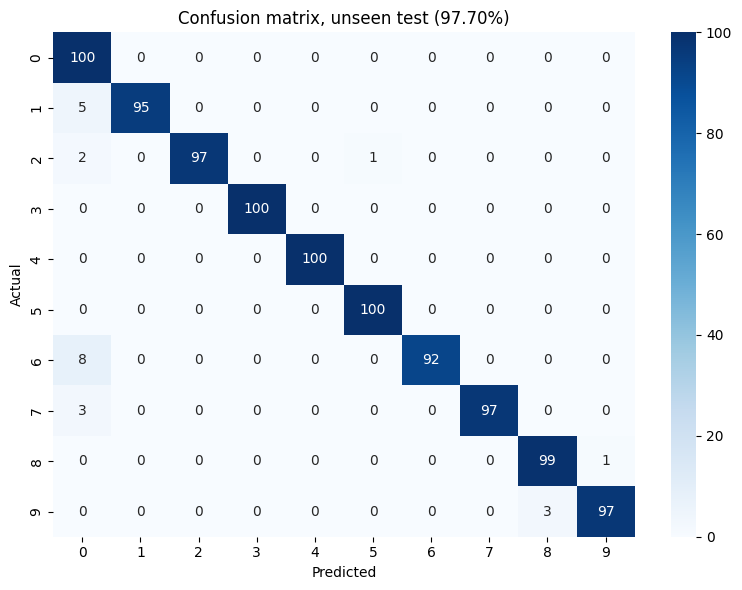

In [ ]:
# Score on the unseen 20%
probs = model.predict(X_all[test_idx], verbose=0)
pred = probs.argmax(axis=1)
test_acc = accuracy_score(y[test_idx], pred) * 100
print(f"TEST ACCURACY (unseen 20%, {len(test_idx)} signals): {test_acc:.2f}%")
print(f"Macro F1: {f1_score(y[test_idx], pred, average='macro'):.4f}\n")
report = classification_report(y[test_idx], pred, target_names=class_names, digits=4, zero_division=0)
print(report)
open(f"{OUTPUT_DIR}/test_classification_report.txt","w").write(f"Test accuracy: {test_acc:.2f}%\n\n{report}")

cm = confusion_matrix(y[test_idx], pred, labels=classes)
plt.figure(figsize=(8,6)); sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.title(f"Confusion matrix, unseen test ({test_acc:.2f}%)"); plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.tight_layout(); plt.savefig(f"{OUTPUT_DIR}/test_confusion.png", dpi=150); plt.show()

pd.DataFrame({"signal_index":test_idx,"true":y[test_idx],"pred":pred,"confidence":probs.max(1)}).to_csv(f"{OUTPUT_DIR}/test_predictions.csv", index=False)

In [ ]:
# 5-fold CV on the pool as well, same as final.ipynb
if RUN_CV:
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    cv_accs = []
    for k, (tr, va) in enumerate(skf.split(trainval_idx, y[trainval_idx]), start=1):
        tr_idx, va_idx = trainval_idx[tr], trainval_idx[va]
        f_idx, e_idx = train_test_split(tr_idx, test_size=0.15, random_state=RANDOM_STATE, stratify=y[tr_idx])
        tf.keras.backend.clear_session(); set_seed()
        m = build_model(len(classes), N_SAMPLES)
        m.fit(X_all[f_idx], y[f_idx], validation_data=(X_all[e_idx], y[e_idx]),
              epochs=EPOCHS, batch_size=32, callbacks=make_callbacks(), verbose=0)
        acc = accuracy_score(y[va_idx], m.predict(X_all[va_idx], verbose=0).argmax(1)) * 100
        cv_accs.append(acc); print(f"Fold {k}/5: {acc:.2f}%")
    print(f"Mean {np.mean(cv_accs):.2f}%  Std {np.std(cv_accs):.2f}%")

Fold 1/5: 97.25%
Fold 2/5: 96.62%
Fold 3/5: 97.62%
Fold 4/5: 97.38%
Fold 5/5: 97.12%
Mean 97.20%  Std 0.33%
